## Importação e Limpeza

In [1]:
# !pip install pandas
# !pip install matplotlib.pyplot
# !pip install seaborn
# !pip install openpyxl
# !pip install scikit-learn
# !pip install Plotly
# !pip install --upgrade nbformat


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_samples
import plotly.express as px
from re import search
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

In [3]:
df:pd.DataFrame = pd.read_excel("../data/raw/ICB_DADOS_2026.xlsx")

In [4]:
df.columns

Index(['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco',
       'Quantidade', 'PPK'],
      dtype='str')

In [5]:
# dividir por produto
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
             'Pão Francês',                    'Óleo',
                  'Açúcar',        'Farinha de Trigo',
                  'Feijão',            'Banana Prata',
                   'Leite',                  'Tomate',
                  'Batata',           'Banana Nanica',
       'Carne Bovina Acem',            'Frango Peito',
      'Carne Suína Pernil',        'Frango Sobrecoxa',
                     'Ovo',       'Macarrão com Ovos',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra',                 'Farinha',
                'Macarrão',              'Carne Acem',
        'Carne Coxão Mole',                     'Pão',
            'Carne Pernil',                  'Pernil']
Length: 30, dtype: str

### Limpeza

In [6]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
...,...,...,...,...,...,...,...,...
46259,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
46260,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
46261,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
46262,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


In [7]:
MIN_MESES = 28

meses_por_estab = df.groupby('Estab')['Mes_Ano_Data'].nunique().sort_values(ascending=False)
estabs_validos = meses_por_estab[meses_por_estab >= MIN_MESES].index

linhas_antes = len(df)
df = df[df['Estab'].isin(estabs_validos)].reset_index(drop=True)

print(f'Mercados mantidos: {len(estabs_validos)} de {len(meses_por_estab)}')
print(f'Linhas removidas: {linhas_antes - len(df)} de {linhas_antes} ({(linhas_antes - len(df)) / linhas_antes:.1%})')
print('\nMercados removidos (meses de histórico):')
print(meses_por_estab[meses_por_estab < MIN_MESES])

Mercados mantidos: 28 de 51
Linhas removidas: 2111 de 46264 (4.6%)

Mercados removidos (meses de histórico):
Estab
SUP_29    18
SUP_30    14
SUP_44     3
SUP_45     2
SUP_10     2
SUP_14     2
SUP_23     2
SUP_09     1
ALT_49     1
SUP_03     1
ALT_48     1
SUP_02     1
SUP_05     1
ALT_28     1
ALT_35     1
ALT_26     1
SUP_25     1
SUP_18     1
SUP_21     1
SUP_31     1
SUP_37     1
SUP_40     1
SUP_42     1
Name: Mes_Ano_Data, dtype: int64


In [8]:
df['Marca'][df['Produto']=='Café'].unique()

array(['Pilão', 'Melita', '3 Corações', 'Caboclo', 'Canecão',
       'São Joaquim', 'Moraes', 'Pelé', 'São', 'União', 'Fort', 'Nescafé',
       nan, '3 corações', 'São Joaquim ', 'Outro'], dtype=object)

Precisamos tratar as marcas 3 corações e São Joaquim.

In [9]:
df.loc[df['Marca'].str.contains('3 corações', case=False, na=False), 'Marca'] = '3 Corações'
df.loc[df['Marca'].str.contains('São Joaquim ', case=False, na=False), 'Marca'] = 'São Joaquim'

In [10]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
3,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
4,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
...,...,...,...,...,...,...,...,...
44148,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
44149,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
44150,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
44151,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


In [11]:
nomes = {
    "Farinha de Trigo": "Farinha",
    "Carne Acem": "Carne Bovina Acem",
    "Pão Francês": "Pão",
    "Macarrão com Ovos": "Macarrão",
    "Carne Coxão Mole": "Carne Bovina Coxão Mole",
    "Carne Pernil": "Pernil",
    "Carne Suína Pernil": "Pernil",
}
df["Produto"] = df["Produto"].replace(nomes)


In [12]:
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
                     'Pão',                  'Açúcar',
                 'Farinha',                  'Feijão',
                    'Óleo',            'Banana Prata',
                   'Leite',                  'Tomate',
           'Banana Nanica',                  'Batata',
       'Carne Bovina Acem',            'Frango Peito',
                  'Pernil',        'Frango Sobrecoxa',
                     'Ovo',                'Macarrão',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra']
Length: 23, dtype: str

In [13]:
duplicadas = df[df.duplicated(keep=False)]

print(f"Linhas repetidas: {df.duplicated().sum()}")
duplicadas.sort_values(["Mes_Ano_Data", "Estab", "Produto"])

Linhas repetidas: 1742


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
1416,2022-10-01,2022-10-24,SUP_38,Farinha,Dona Benta,6.75,1.0,6.750000
1417,2022-10-01,2022-10-24,SUP_38,Farinha,Dona Benta,6.75,1.0,6.750000
2107,2022-11-01,2022-11-21,SUP_24,Banana Prata,NaN,7.99,1.0,7.990000
2108,2022-11-01,2022-11-21,SUP_24,Banana Prata,NaN,7.99,1.0,7.990000
2114,2022-11-01,2022-11-18,SUP_34,Banana Prata,NaN,7.99,1.0,7.990000
...,...,...,...,...,...,...,...,...
41459,2026-05-01,NaT,SUP_50,Óleo,Soya,7.99,0.9,8.877778
41496,2026-05-01,NaT,SUP_50,Óleo,Liza,7.99,0.9,8.877778
41497,2026-05-01,NaT,SUP_50,Óleo,Soya,7.99,0.9,8.877778
42067,2026-06-01,NaT,SUP_04,Feijão,Outro,8.99,1.0,8.990000


In [14]:
df = df.drop_duplicates()

## Análise Café

In [15]:
df_cafe = df[df['Produto'] == 'Café']
df_cafe = df_cafe.sort_values('Mes_Ano_Data')

df_pilao = df[df['Marca'] == 'Pilão']
df_3coracoes = df[df['Marca'] == '3 Corações']
df_caboclo = df[df['Marca'] == 'Caboclo']

x = np.array(df_caboclo['Mes_Ano_Data'])
y = np.array(df_caboclo['Preco'])

In [16]:
df_cafe['Marca'].unique()

array(['Pilão', 'Caboclo', '3 Corações', 'Moraes', 'Pelé', 'Canecão',
       'São Joaquim', 'Melita', 'Nescafé', 'São', 'Fort', 'União', nan,
       'Outro'], dtype=object)

In [17]:
df_cafe.groupby('Marca').count().sort_values('Quantidade', ascending=False)


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Preco,Quantidade,PPK
Marca,,,,,,,
3 Corações,1083,896,1083,1083,1083,1083,1083
Melita,895,757,895,895,895,895,895
Pilão,809,685,809,809,809,809,809
Caboclo,775,646,775,775,775,775,775
Canecão,690,556,690,690,690,690,690
São Joaquim,218,173,218,218,218,218,218
Moraes,172,129,172,172,172,172,172
União,155,121,155,155,155,155,155
Fort,53,33,53,53,53,53,53


In [18]:
df_cafe = df_cafe[df_cafe['Marca'] != 'Nescafé']
df_cafe = df_cafe[df_cafe['Marca'] != 'São'] 

In [19]:
df_cafe

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
49,2022-09-01,2022-09-21,SUP_39,Café,Pilão,25.99,0.5,51.98
229,2022-09-01,2022-09-12,SUP_43,Café,Caboclo,16.90,0.5,33.80
228,2022-09-01,2022-09-26,SUP_24,Café,Caboclo,16.98,0.5,33.96
227,2022-09-01,2022-09-21,SUP_46,Café,3 Corações,16.98,0.5,33.96
226,2022-09-01,2022-09-26,SUP_41,Café,Pilão,16.99,0.5,33.98
...,...,...,...,...,...,...,...,...
43437,2026-08-01,NaT,SUP_24,Café,Caboclo,29.98,0.5,59.96
43436,2026-08-01,NaT,SUP_24,Café,3 Corações,32.90,0.5,65.80
43435,2026-08-01,NaT,SUP_24,Café,Melita,32.99,0.5,65.98
43398,2026-08-01,NaT,SUP_13,Café,Pelé,30.89,0.5,61.78


In [20]:
def plotar_grafico_por_cada_marca(df, marca:list):
    for m in marca:
        df_marca = df[df['Marca'] == m]
        plt.figure(figsize=(10, 6))
        sns.lineplot(data=df_marca, x='Mes_Ano_Data', y='Preco', marker='o')
        plt.title(f'Preço do Café - {m}')
        plt.xlabel('Mês/Ano')
        plt.ylabel('Preço')
        plt.xticks(rotation=45)
        plt.grid()
        plt.tight_layout()
        plt.show()

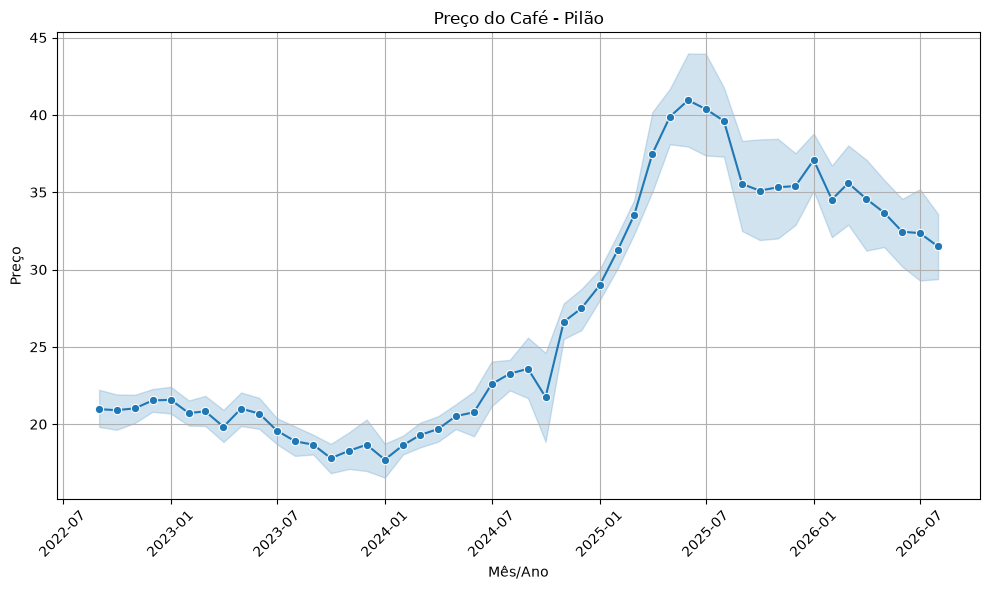

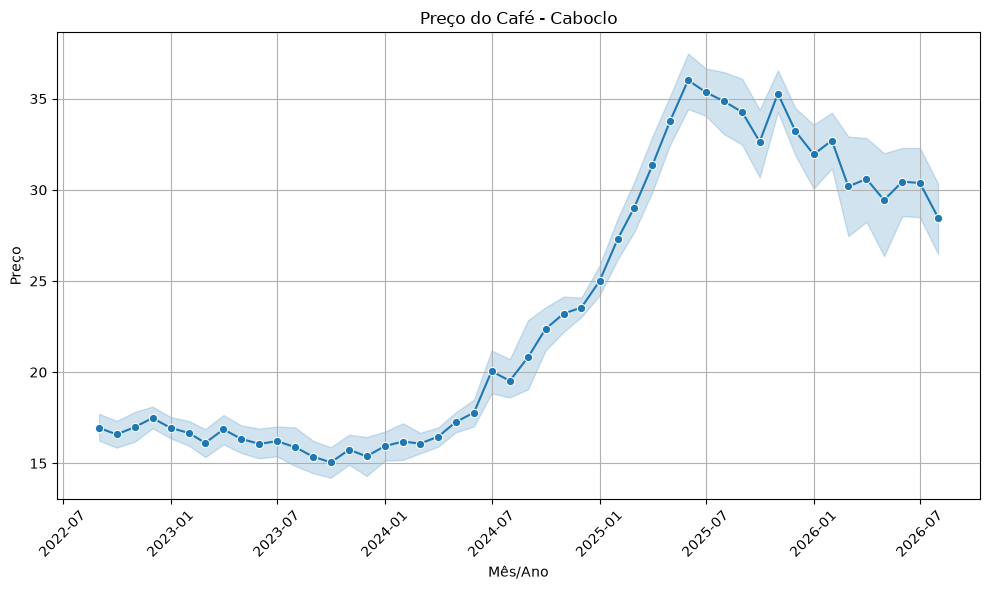

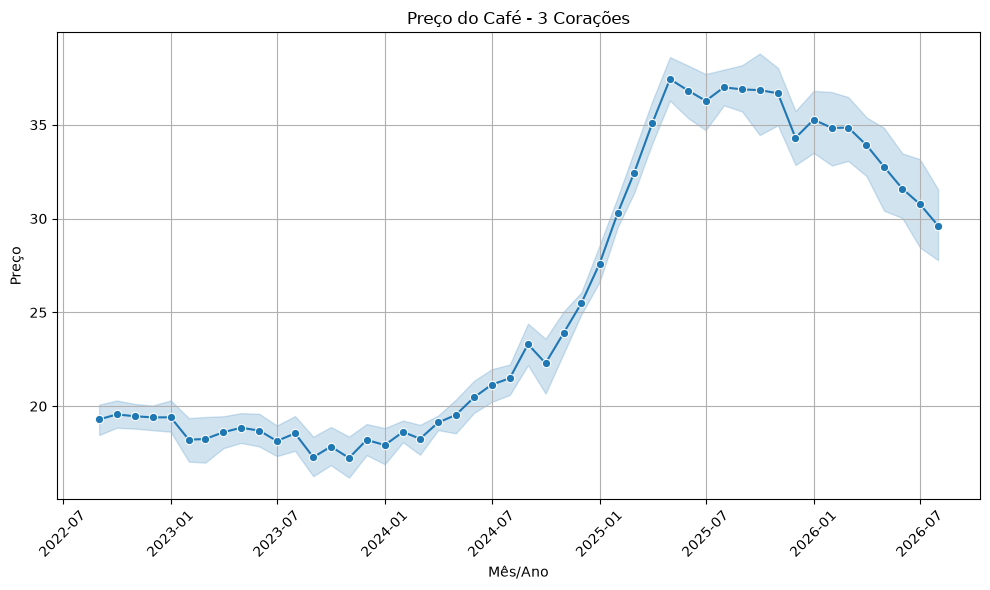

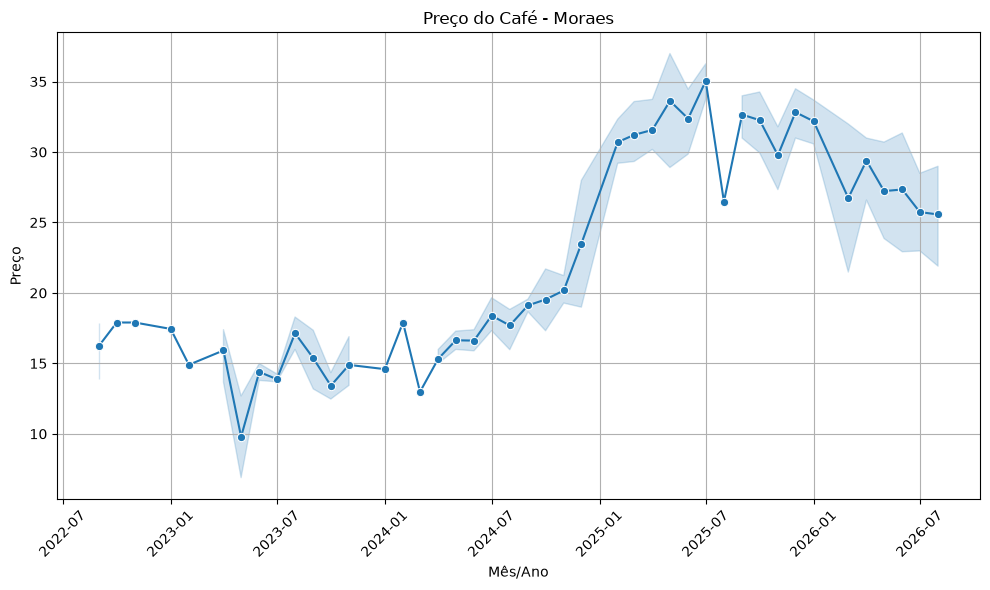

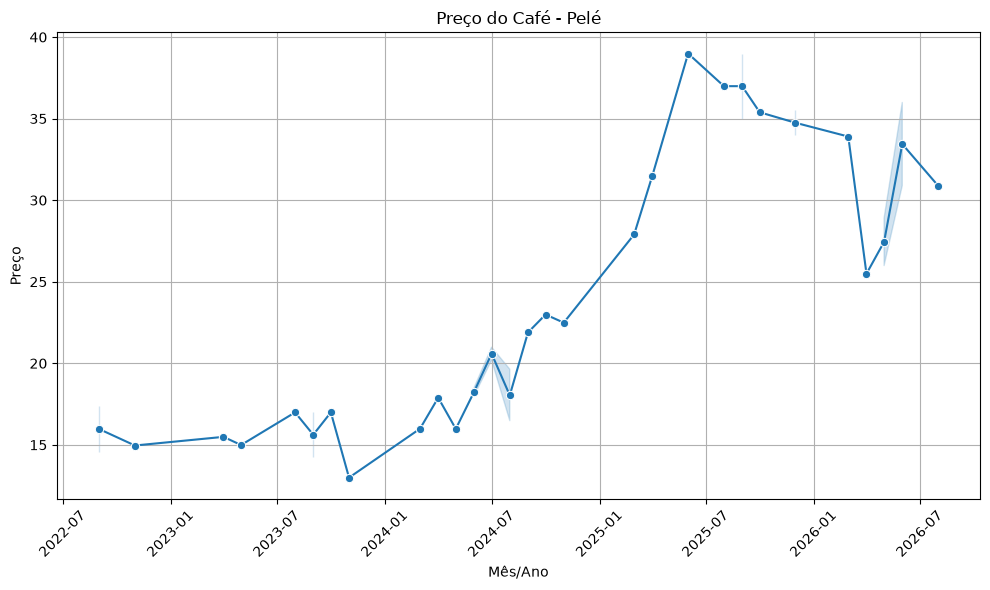

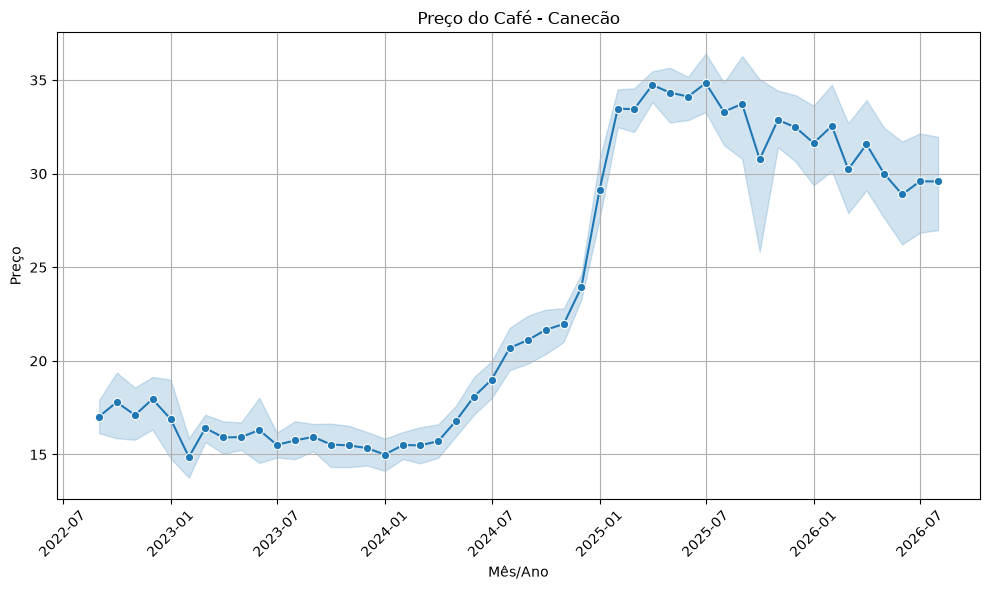

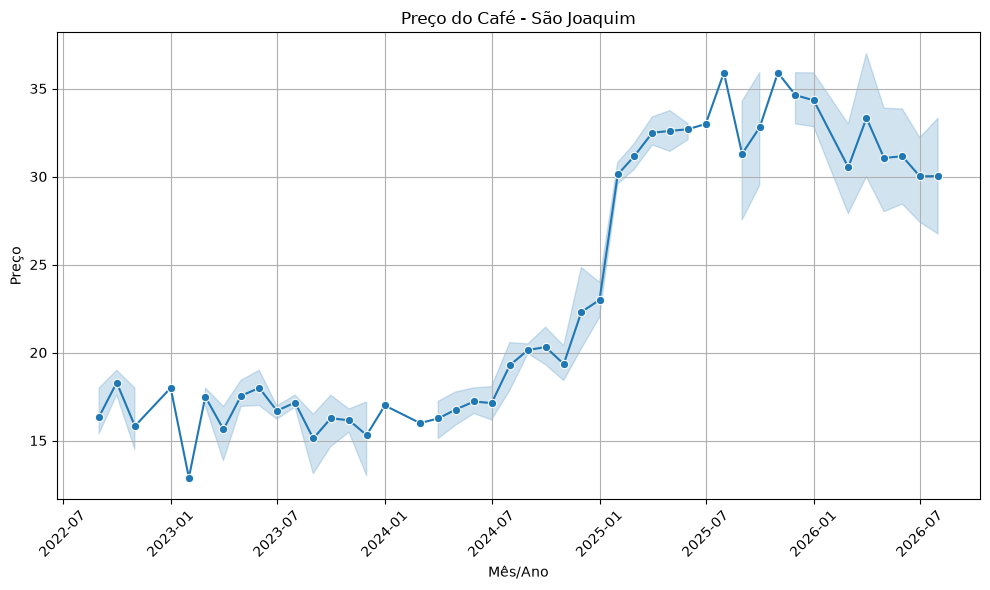

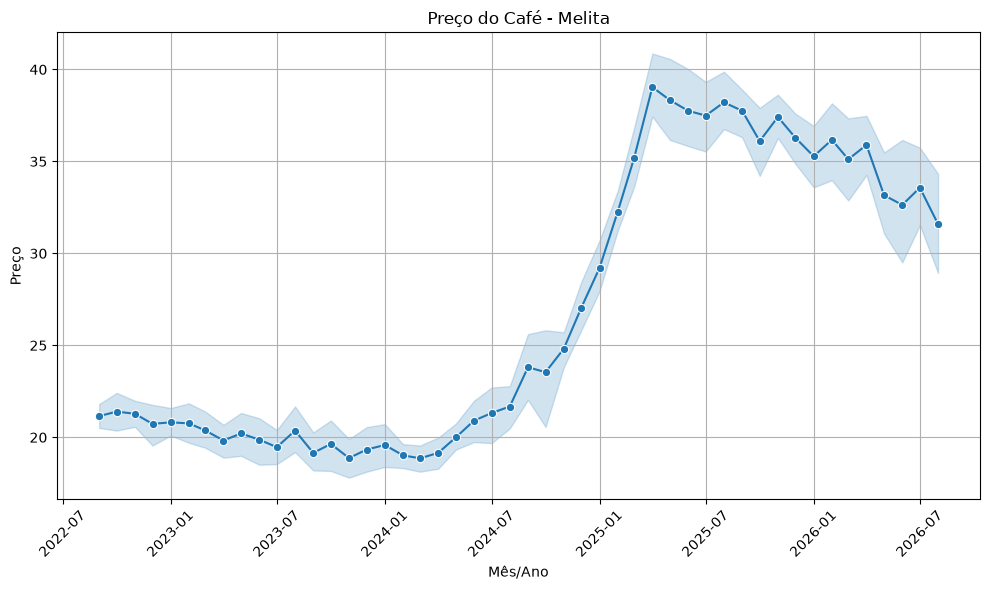

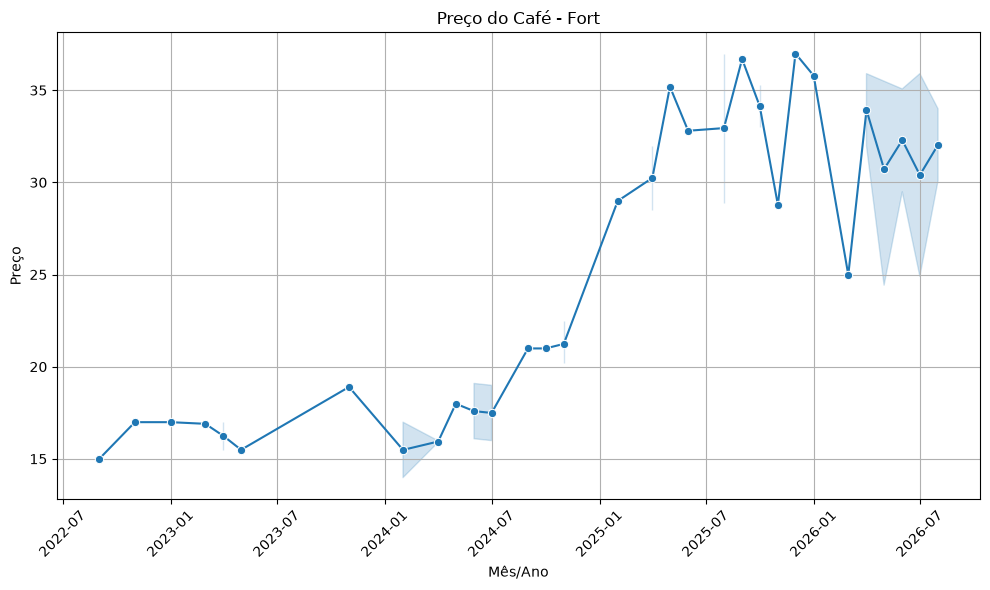

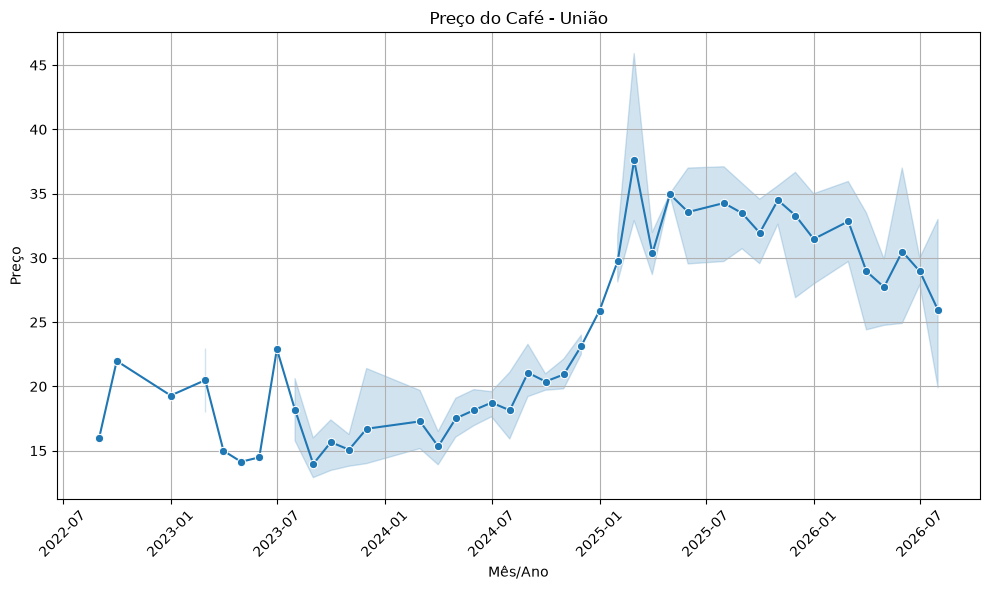

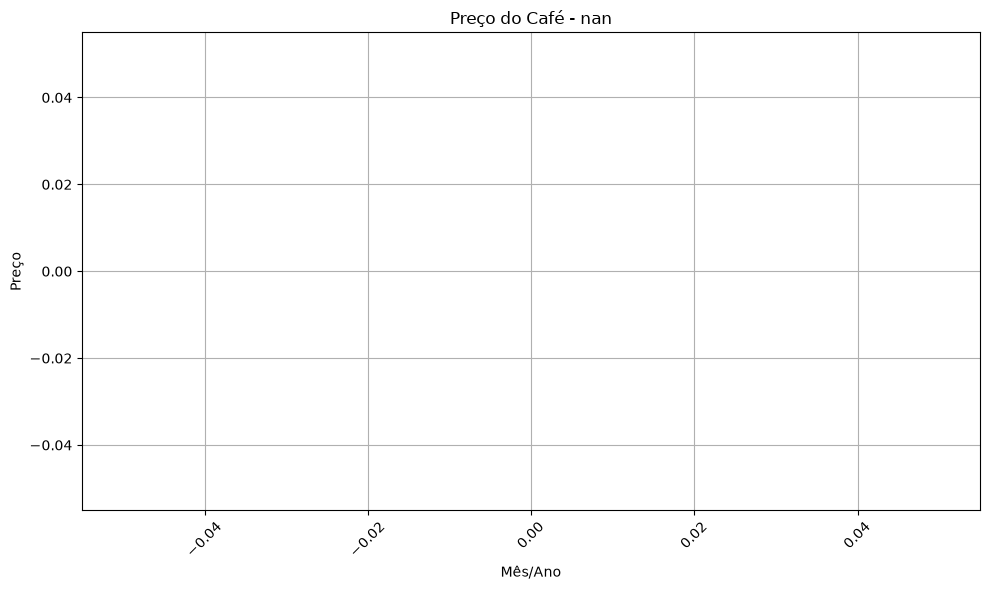

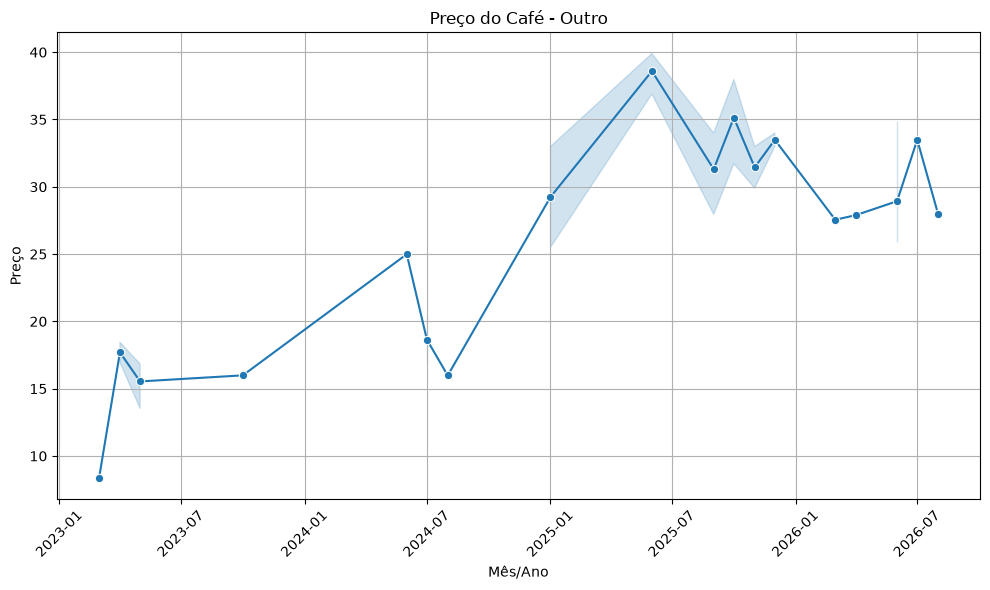

In [21]:
plotar_grafico_por_cada_marca(df_cafe, df_cafe['Marca'].unique())

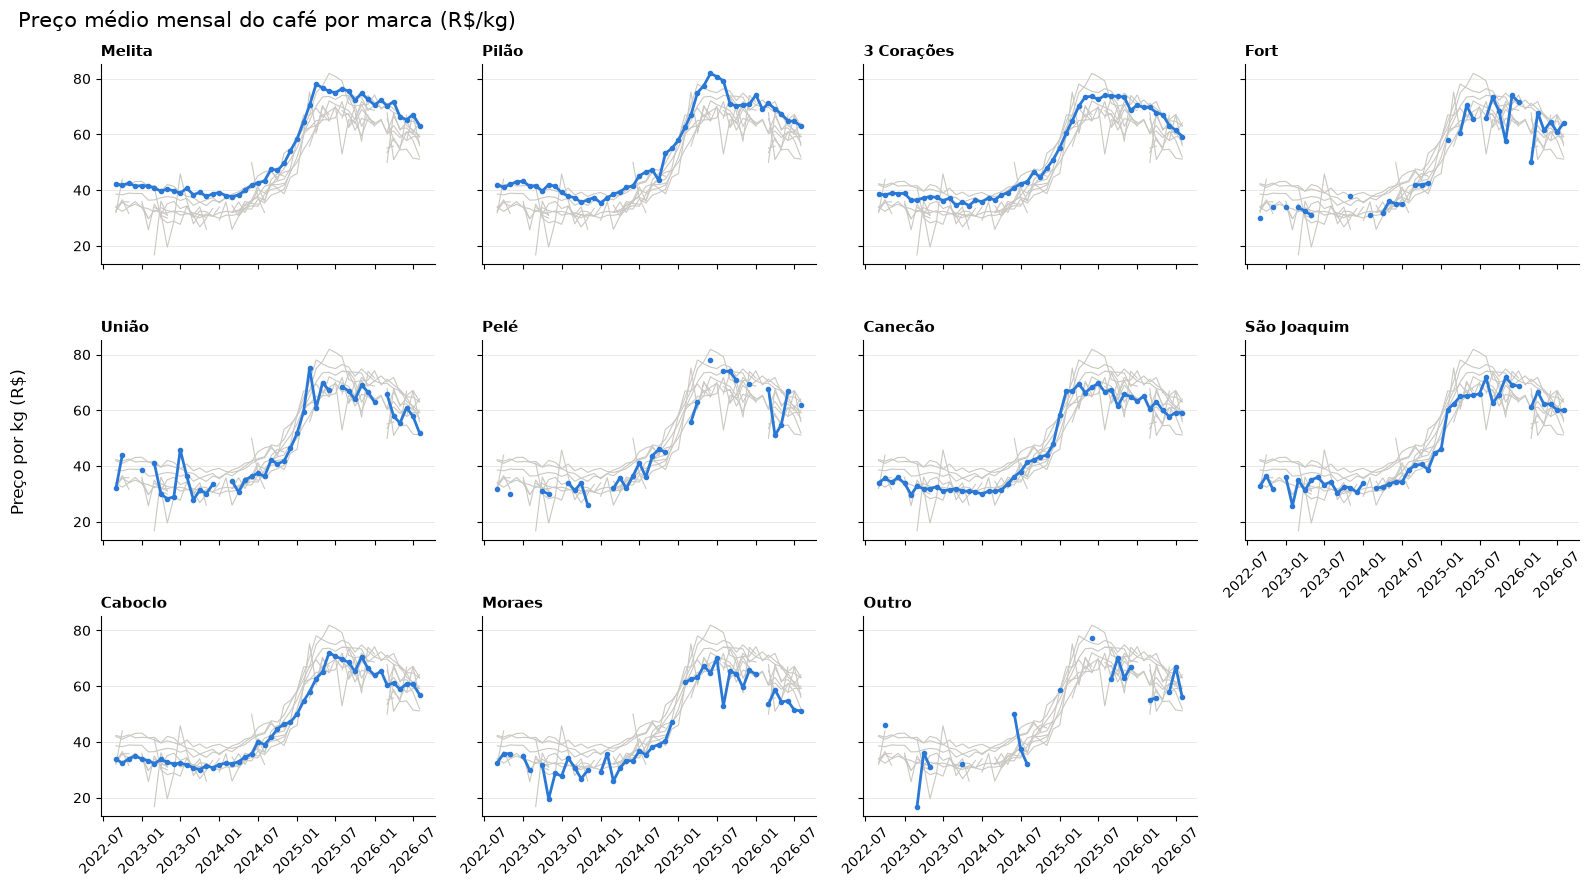

In [22]:
# Padroniza os nomes das marcas (espaços sobrando, maiúsculas/minúsculas, registros incompletos)
marca = df_cafe['Marca'].str.strip().str.title()
marca = marca.replace({'São': 'São Joaquim', 'Nescafé': 'Outro'}).fillna('Outro')

# Média mensal do preço por kg (PPK) de cada marca: uma coluna por marca, uma linha por mês
cafe_mensal = (
    df_cafe.assign(Marca=marca)
    .groupby(['Mes_Ano_Data', 'Marca'])['PPK']
    .mean()
    .unstack('Marca')
)

# Ordena da marca mais cara para a mais barata, deixando "Outro" por último
ordem = cafe_mensal.drop(columns='Outro').mean().sort_values(ascending=False).index.tolist() + ['Outro']

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)
for ax, nome in zip(axes.flat, ordem):
    # Todas as marcas em cinza como referência, com a marca do painel em destaque
    ax.plot(cafe_mensal.index, cafe_mensal, color='#c9c8c2', linewidth=0.8)
    ax.plot(cafe_mensal.index, cafe_mensal[nome], color='#2a78d6', linewidth=2, marker='o', markersize=3)
    ax.set_title(nome, loc='left', fontsize=11, fontweight='bold')
    ax.grid(axis='y', color='#e8e7e2', linewidth=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', rotation=45)

# Remove os painéis que sobraram na grade e devolve o eixo de datas ao painel logo acima
for ax in axes.flat[len(ordem):]:
    ax.remove()
axes[1, 3].tick_params(axis='x', labelbottom=True)

fig.suptitle('Preço médio mensal do café por marca (R$/kg)', x=0.01, ha='left', fontsize=15)
fig.supylabel('Preço por kg (R$)', x=0.005)
fig.tight_layout(rect=(0.015, 0, 1, 1))
plt.show()

Tratamento simples para deixar tudo com letra minuscula, filtro para pegar somentes cafes na base e por fim transformando o tipo da data

In [23]:
cafe = df[df["Produto"] == "Café"]
cafe.columns = df.columns.str.lower().str.strip()
cafe.marca = cafe.marca.str.strip()
cafe.marca = cafe.marca.str.lower()
cafe['data_coleta'] = pd.to_datetime(cafe['data_coleta'])

Analisamos a quantidade de cafes por marca para ver se seria bom tirarmos alguns outliers

In [24]:
print(cafe["marca"].value_counts())

marca
3 corações     1083
melita          895
pilão           809
caboclo         775
canecão         690
são joaquim     218
moraes          172
união           155
fort             53
pelé             40
outro            37
são               2
nescafé           1
Name: count, dtype: int64


In [25]:
df_filtro_de_cafe=cafe["marca"].value_counts()
df_filtro_de_cafe =df_filtro_de_cafe.to_frame()
media_dados=df_filtro_de_cafe.mean()
print(media_dados)
std_dados=df_filtro_de_cafe.std()
print(std_dados)

count    379.230769
dtype: float64
count    402.329499
dtype: float64


In [26]:
print(media_dados-std_dados)

count   -23.09873
dtype: float64


In [27]:
df_filtro_de_cafe[df_filtro_de_cafe>(media_dados-2*std_dados)]

,count
marca,
3 corações,1083
melita,895
pilão,809
caboclo,775
canecão,690
são joaquim,218
moraes,172
união,155
fort,53


In [28]:
df_outliers=df_filtro_de_cafe[df_filtro_de_cafe<(media_dados-2*std_dados)]
print(df_outliers)

             count
marca             
3 corações     NaN
melita         NaN
pilão          NaN
caboclo        NaN
canecão        NaN
são joaquim    NaN
moraes         NaN
união          NaN
fort           NaN
pelé           NaN
outro          NaN
são            NaN
nescafé        NaN


Retirando alguns cafes com pouco impacto

In [29]:
cafe = cafe[cafe["marca"] != "São Joaquim "]
cafe = cafe[cafe["marca"] != "nescafé"]
cafe = cafe[cafe["marca"] != "são"]
print(cafe["marca"].value_counts())

marca
3 corações     1083
melita          895
pilão           809
caboclo         775
canecão         690
são joaquim     218
moraes          172
união           155
fort             53
pelé             40
outro            37
Name: count, dtype: int64


Teste para ver se retirar os de valores muito baixo influenciria nos resto dos graficos porém concluimos que apenas os 5 cafes mais listados eram o suficiente para nossa analise.

In [30]:
teste = cafe.groupby("mes_ano_data")["ppk"].mean()
print(teste.describe())

count    48.000000
mean     50.106537
std      14.878847
min      33.870909
25%      36.760847
50%      42.475931
75%      65.769489
max      73.211591
Name: ppk, dtype: float64


In [31]:
top_5 = ['3 corações',"melita","pilão","caboclo","canecão"]
cafe = cafe[cafe["marca"].isin(top_5)]
cafe.marca.value_counts()

marca
3 corações    1083
melita         895
pilão          809
caboclo        775
canecão        690
Name: count, dtype: int64

In [32]:
mensal = cafe.groupby("mes_ano_data")["ppk"].mean()
print(mensal.describe())

count    48.000000
mean     50.740196
std      15.034964
min      34.437391
25%      37.251835
50%      43.608500
75%      66.931994
max      74.054146
Name: ppk, dtype: float64


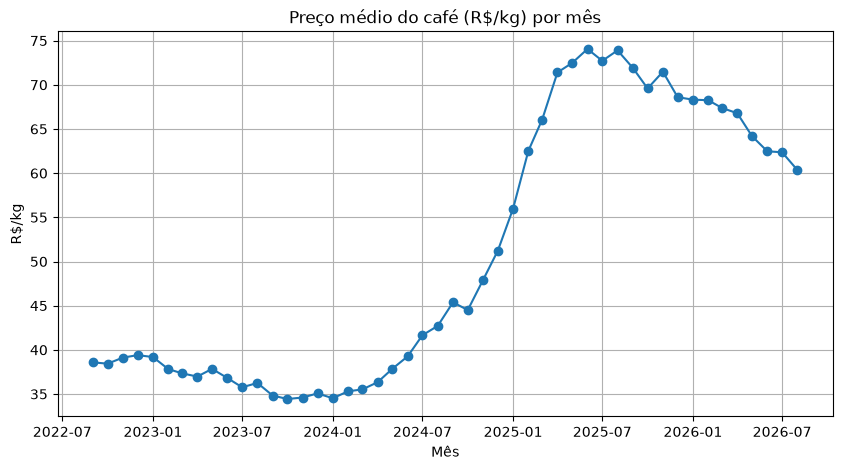

In [33]:
plt.figure(figsize=(10, 5))
plt.plot(mensal.index, mensal.values, marker="o")
plt.title("Preço médio do café (R$/kg) por mês")
plt.xlabel("Mês")
plt.ylabel("R$/kg")
plt.grid(True)

Lembrando que no caso os valores tem que ser dividos por 2 ja que todos os pacotes tem 500g

In [34]:
mensal = (cafe.groupby("mes_ano_data")["ppk"].mean())/2
print(mensal.describe())

count    48.000000
mean     25.370098
std       7.517482
min      17.218696
25%      18.625918
50%      21.804250
75%      33.465997
max      37.027073
Name: ppk, dtype: float64


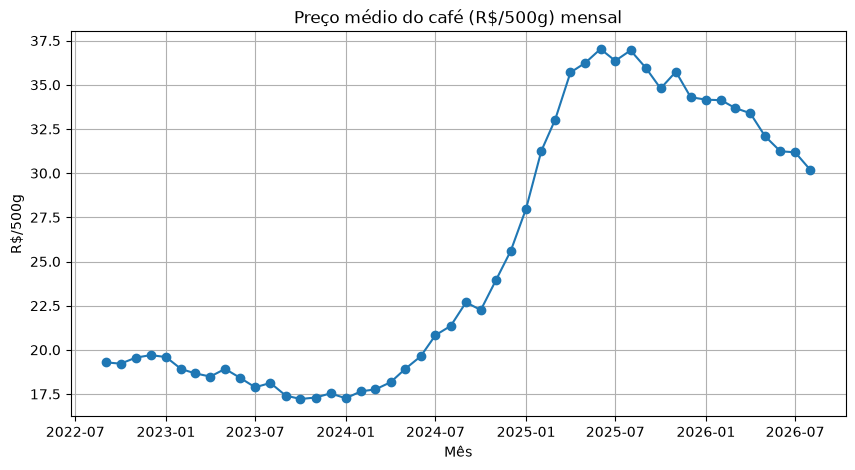

In [35]:
plt.figure(figsize=(10, 5))
plt.plot(mensal.index, mensal.values, marker="o")
plt.title("Preço médio do café (R$/500g) mensal")
plt.xlabel("Mês")
plt.ylabel("R$/500g")
plt.grid(True)

O grafico não mudou nada no quesito visual, apenas diminiu o a escala por 2 ja que todos os pacotes analisados na base dados é de 500g

Aqui pegando uma visão individual de cada café que nos fez realmente tirar o resto dos muito abaixos em qauntidades.

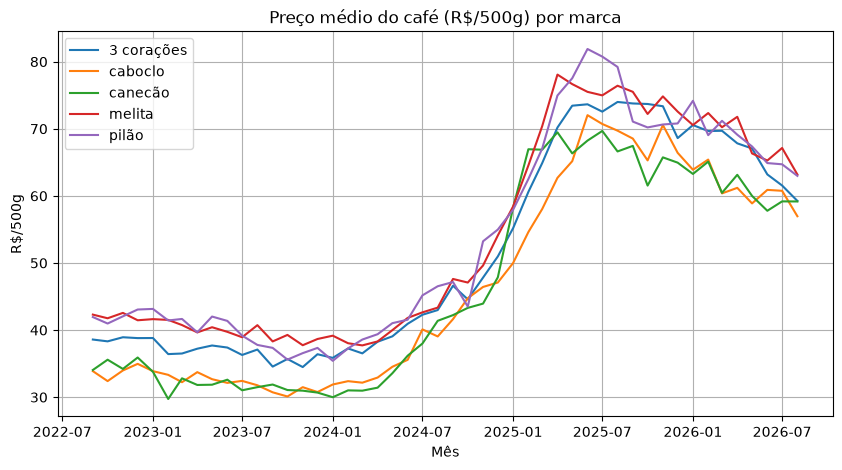

In [36]:
mensal_marca = cafe.groupby(["mes_ano_data", "marca"])["ppk"].mean().unstack()
plt.figure(figsize=(10, 5))
for marca in mensal_marca.columns:
    plt.plot(mensal_marca.index, mensal_marca[marca], label=marca)

plt.title("Preço médio do café (R$/500g) por marca")
plt.xlabel("Mês")
plt.ylabel("R$/500g")
plt.legend()
plt.grid(True)
plt.show()

Com algumas pesquisas no google, esses anos tiveram muitos efeitos climaticos que ocasiona a alta e baixa no preço do café (EL NINÕ) é uma delas
Para mostrar graficamente pegamos dados oficiais da CONAB que mostra os dados das safras de cafe anualmente.

In [37]:
# Dados oficiais da Conab consolidados (2022 a 2026)
dados_conab = {
    "Ano": [2022, 2023, 2024, 2025, 2026, 2027],
    "Prod_Total_Milhoes_Sacas": [50.9, 55.1, 54.2, 56.5, 67.6, 65.0],
    "Prod_Arabica_Milhoes_Sacas": [32.7, 38.9, 39.6, 35.8, 48.2, 43.5],
    "Prod_Conilon_Milhoes_Sacas": [18.2, 16.2, 14.6, 20.7, 19.4, 21.5],
    "Ciclo_Bienal_Arabica": ["Alta", "Baixa", "Alta (Quebra Climática)", "Baixa", "Alta (Recorde)", "Baixa (Previsão)"],
    "Variacao_Anual_Total_%": [6.7, 8.2, -1.6, 4.2, 19.6, -3.8]
}

conab = pd.DataFrame(dados_conab)
conab.columns = conab.columns.str.lower().str.strip()

<module 'matplotlib.pyplot' from '/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/matplotlib/pyplot.py'>

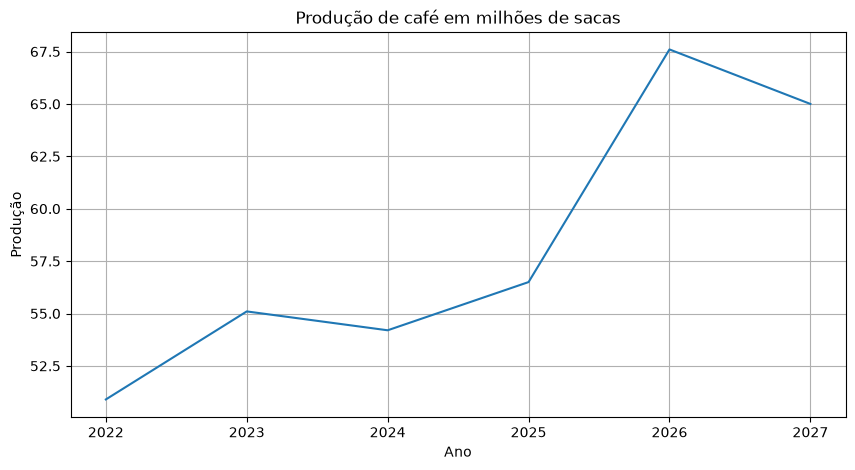

In [38]:
plt.figure(figsize=(10, 5))
plt.plot(conab["ano"], conab["prod_total_milhoes_sacas"], label="Total")
plt.grid(True)
plt.title("Produção de café em milhões de sacas")
plt.xlabel("Ano")
plt.ylabel("Produção")
plt

plotando os 2 graficos juntos para ver a oposição

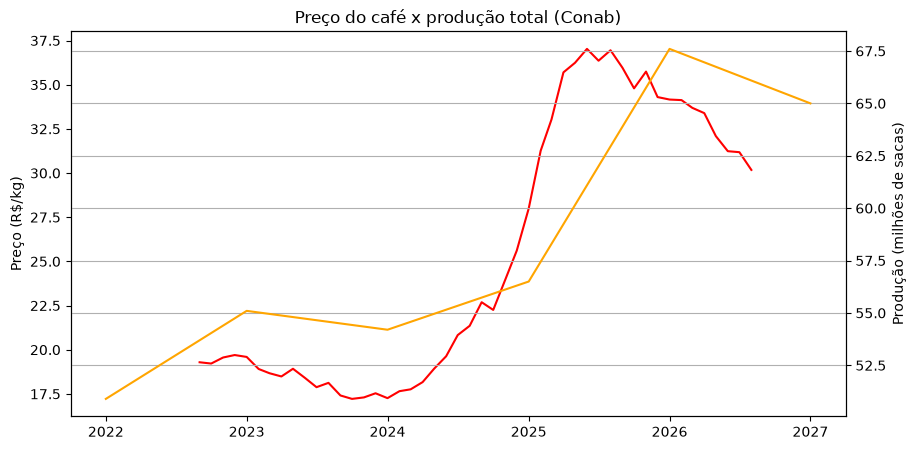

In [39]:
conab["ano"] = pd.to_datetime(conab["ano"].astype(str), format="%Y")
fig, ax1 = plt.subplots(figsize=(10, 5))


ax1.plot(mensal.index, mensal.values, color="red")
ax1.set_ylabel("Preço (R$/500g)")

ax2 = ax1.twinx()
ax2.plot(conab["ano"], conab["prod_total_milhoes_sacas"], color="orange")   # marker deixa claro que são pontos anuais
ax2.set_ylabel("Produção (milhões de sacas)")
plt.title("Preço do café x produção total (Conab)")
plt.grid(True)
plt.show()

Aqui podemos ver que o clima realmente é o fator decisivo em sua variabilidade de preço, pois quando a sagra cresce o preço diminui e vice versa

### Predição do preço para o proximo ano

2026-09-01    29.763792
2026-10-01    29.295314
2026-11-01    28.891457
2026-12-01    28.543307
2027-01-01    28.243182
2027-02-01    27.984455
2027-03-01    27.761416
2027-04-01    27.569144
2027-05-01    27.403393
2027-06-01    27.260506
2027-07-01    27.137329
2027-08-01    27.031142
Freq: MS, Name: simulation, dtype: float64


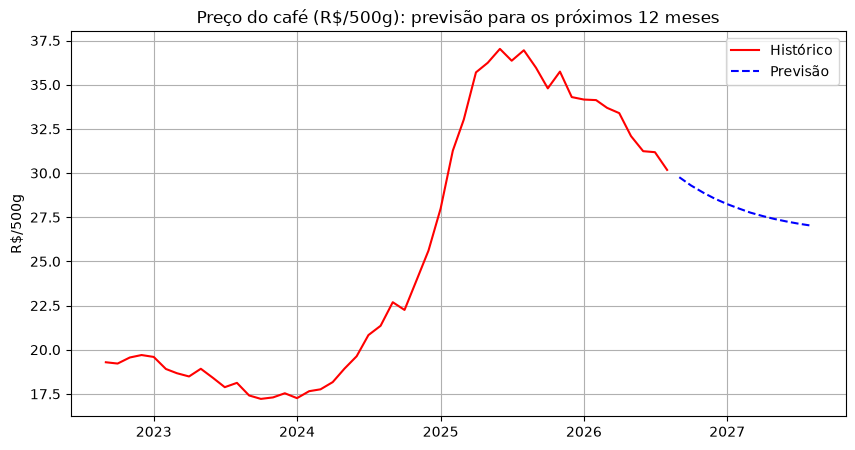

In [40]:
serie = mensal.asfreq("MS") #mensal

# Modelo com tendência aditiva, seasonal=None porque só temos 4 anos
modelo = ETSModel(serie, error="add", trend="add", damped_trend=True)
resultado = modelo.fit()


previsao = resultado.forecast(12) # Proximo ano (2027)
print(previsao)


plt.figure(figsize=(10, 5))
plt.plot(serie.index, serie.values, label="Histórico", color="red")
plt.plot(previsao.index, previsao.values, label="Previsão", color="blue", linestyle="--")
plt.title("Preço do café (R$/500g): previsão para os próximos 12 meses")
plt.ylabel("R$/500g")
plt.legend()
plt.grid(True)
plt.show()

### Juntando as 3 informações

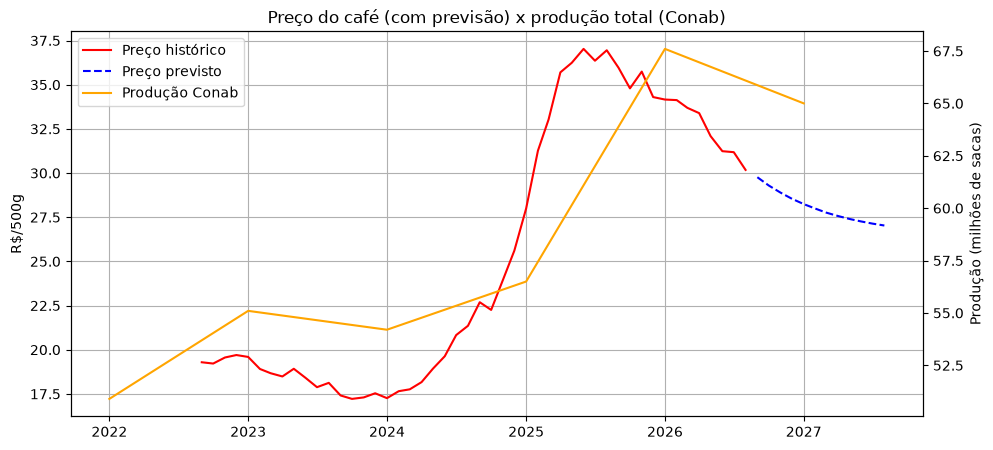

In [41]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(serie.index, serie.values, label="Preço histórico", color="red")
ax1.plot(previsao.index, previsao.values, label="Preço previsto", color="blue", linestyle="--")
ax1.set_ylabel("R$/500g")


ax2 = ax1.twinx()
ax2.plot(conab["ano"], conab["prod_total_milhoes_sacas"],
         label="Produção Conab" , color="orange")
ax2.set_ylabel("Produção (milhões de sacas)")

linhas1, nomes1 = ax1.get_legend_handles_labels()
linhas2, nomes2 = ax2.get_legend_handles_labels()
ax1.legend(linhas1 + linhas2, nomes1 + nomes2, loc="upper left")

plt.title("Preço do café (com previsão) x produção total (Conab)")
ax1.grid(True)
plt.show()

### Conclusão

No começo do trabalho achavamos que a variablidade viria sendo de taxas de impostos(claro que isso tambem influencia) mas ao decorrer do trabalho e de pesquisas externas, concluimos que todos os indicativos vem das grandes mudanças climaticas causadas pelo aquecimento global e outros fenomenos como El Ninõ por exemplo.

As mudanças climaticas acabam com a safra do café, tornando os preços um pouco mais altos para compensar e ter o lucro para reinvestir no proximos meses, mesmo assim, nossas predição e algo meramente teorica, ja que grandes especialista estão otimistas porém com medo das manifestações prevista ao longo do ano que vem.

https://www.canalrural.com.br/agricultura/cafe/cafe-riscos-climaticos-sustentam-precos-apesar-de-perspectiva-favoravel-no-brasil/



https://www.gov.br/conab/pt-br/atuacao/informacoes-agropecuarias/safras/safra-de-cafe/safra-de-cafe-1


## Agrupamentos

In [42]:
years = df["Mes_Ano_Data"].dt.year.unique()

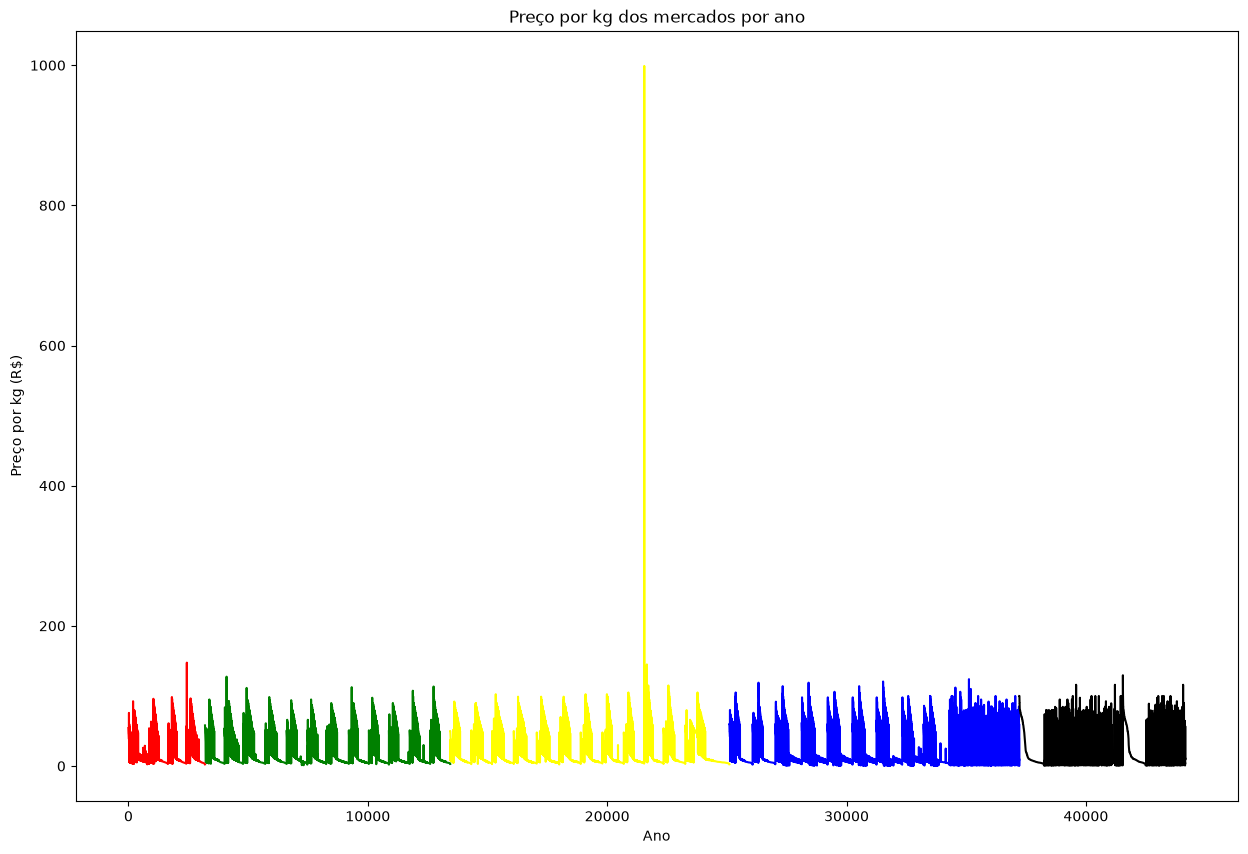

In [43]:
color = ["red","green","yellow","blue","black"]
plt.figure(figsize=(15, 10))
plt.title("Preço por kg dos mercados por ano")
for c, y in enumerate(years):
    plt.plot(df[df["Mes_Ano_Data"].dt.year == y]["PPK"], color = color[c])
plt.xlabel("Ano")
plt.ylabel("Preço por kg (R$)");

Percebemos que existe alguns valores irreais, como preço de carnes saindo à R$0.00 ou uma banana nanica saindo à R$1000.00. Por isso, decidimos criar um dataframe sem esses valores.

In [44]:
df_2 = df.copy()

In [45]:
for produto in df_2["Produto"].unique():
    mediana = df_2[df_2["Produto"] == produto]["PPK"].median()
    irreais = (df_2["Produto"] == produto) & ((df_2["PPK"] > mediana * 3) | (df_2["PPK"] < mediana / 3))
    df_2 = df_2[~irreais]

In [46]:
# quanto o preço está acima/abaixo do "normal" daquele produto naquele mês
# interpretação: 1.0 = na mediana, 0.9 = 10% mais barato, 1.2 = 20% mais caro
mediana_mes = df_2.groupby(["Produto", "Mes_Ano_Data"])["PPK"].transform("median")
df_2["PPK_Relativo"] = df_2["PPK"] / mediana_mes


Criamos uma nova coluna para lidar com possíveis flutuações de preço em um mesmo ano no KMeans. (Exemplo: os preços subirem em Dezembro pode tornar ele um mercado caro na clusterização, mesmo que durante o resto do ano os preços eram estáveis.)

In [47]:
df_2

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK,PPK_Relativo
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20,1.180828
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90,1.174292
2,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99,1.132680
3,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90,1.130719
4,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49,1.100000
...,...,...,...,...,...,...,...,...,...
44148,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99,1.052659
44149,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50,0.920746
44150,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90,1.023565
44151,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99,0.430144


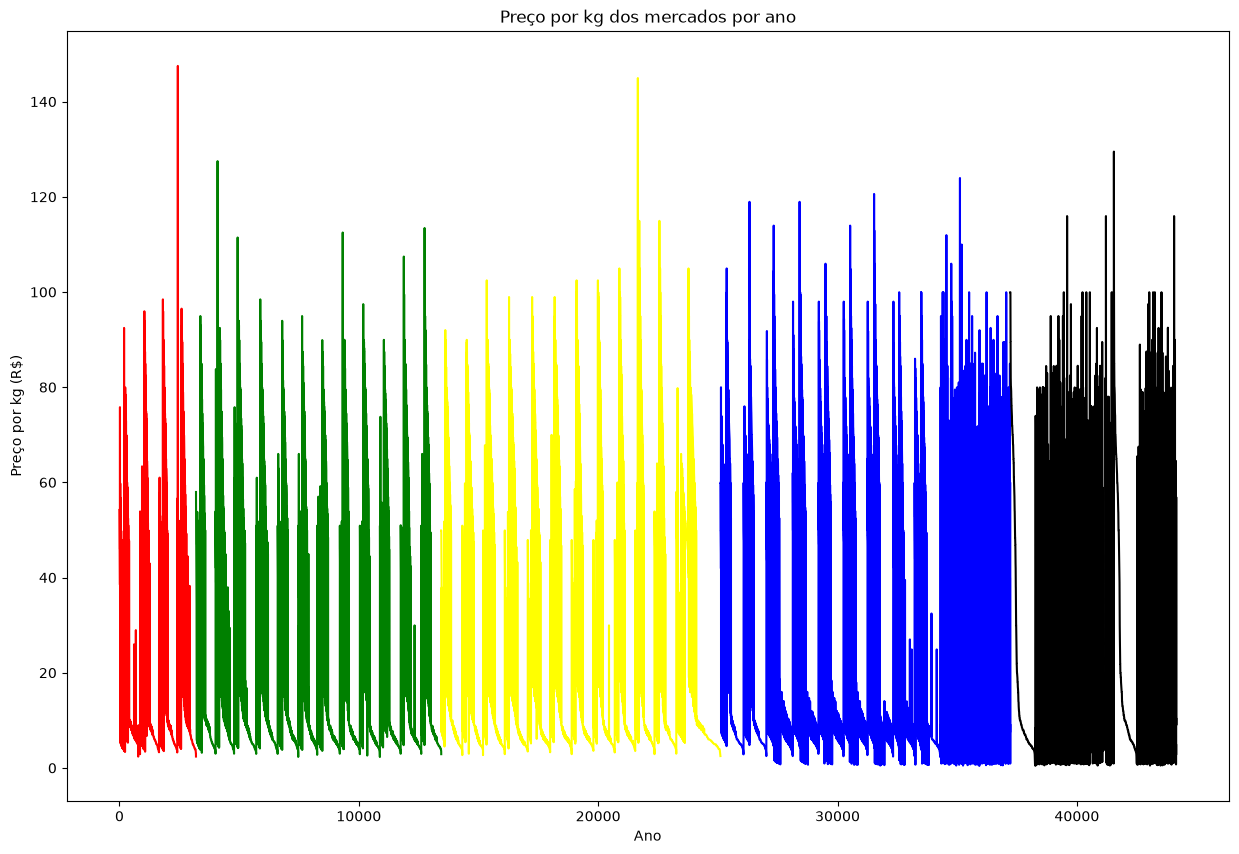

In [48]:
color = ["red","green","yellow","blue","black"]
plt.figure(figsize=(15, 10))
plt.title("Preço por kg dos mercados por ano")
for c, y in enumerate(years):
    plt.plot(df_2[df_2["Mes_Ano_Data"].dt.year == y]["PPK"], color = color[c])
plt.xlabel("Ano")
plt.ylabel("Preço por kg (R$)");

In [49]:
df_2.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
                     'Pão',                 'Farinha',
                  'Feijão',                    'Óleo',
            'Banana Prata',                   'Leite',
                  'Açúcar',                  'Tomate',
           'Banana Nanica',                  'Batata',
       'Carne Bovina Acem',            'Frango Peito',
                  'Pernil',        'Frango Sobrecoxa',
                     'Ovo',                'Macarrão',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra']
Length: 23, dtype: str

In [50]:
produto_escolhido = "arroz".title()
df_produto = df_2[df_2["Produto"] == produto_escolhido]

df_2022 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2022]
df_2023 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2023]
df_2024 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2024]
df_2025 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2025]
df_2026 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2026]

dfs_ano = [df_2022, df_2023, df_2024, df_2025, df_2026]

for df_ano in dfs_ano:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_ano[["PPK_Relativo"]])

    # 3. Criar e treinar o modelo K-Means (exemplo com K=3)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)

    # 4. Obter os rótulos (clusters) de cada linha
    centros = kmeans.cluster_centers_.ravel()
    ordem = sorted(range(3), key=lambda c: centros[c])
    novo_rotulo = {antigo: novo for novo, antigo in enumerate(ordem)}
    df_ano['cluster'] = [novo_rotulo[l] for l in kmeans.labels_]

    # Ver os centroides finais
    print(kmeans.cluster_centers_)

[[ 0.14414088]
 [-1.13290461]
 [ 1.3701328 ]]
[[-0.0308362 ]
 [-1.34251659]
 [ 1.15413646]]
[[ 1.14758704]
 [-1.31190648]
 [ 0.0049619 ]]
[[ 1.05443382]
 [-1.5334763 ]
 [-0.12763359]]
[[-1.38948745]
 [ 1.07993874]
 [-0.05431386]]


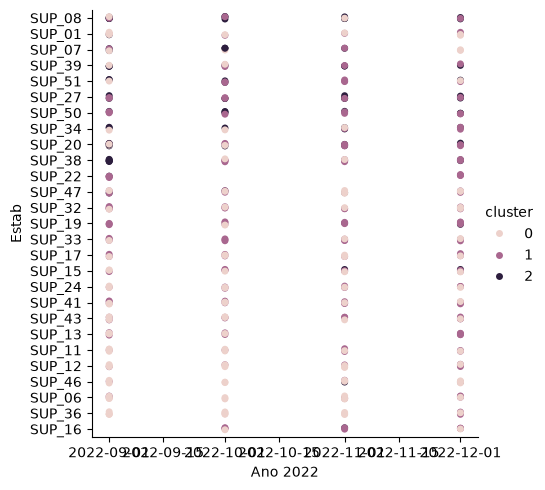

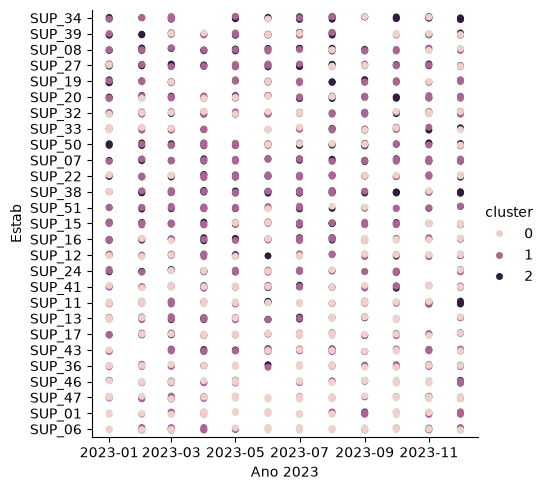

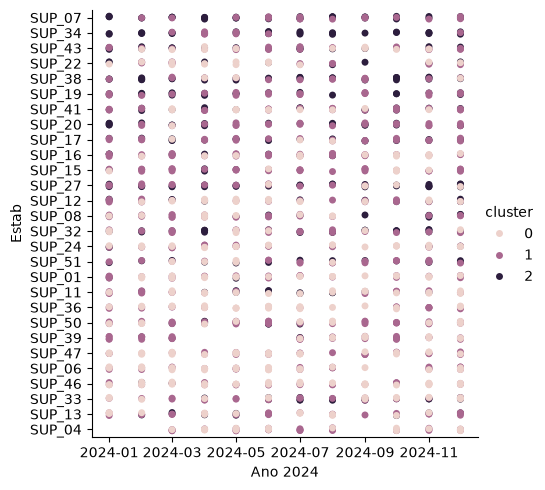

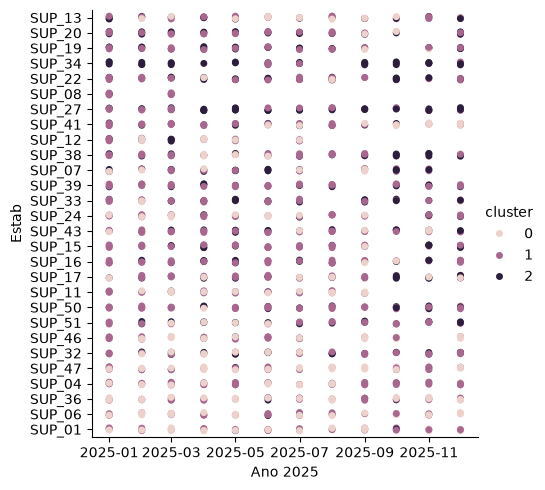

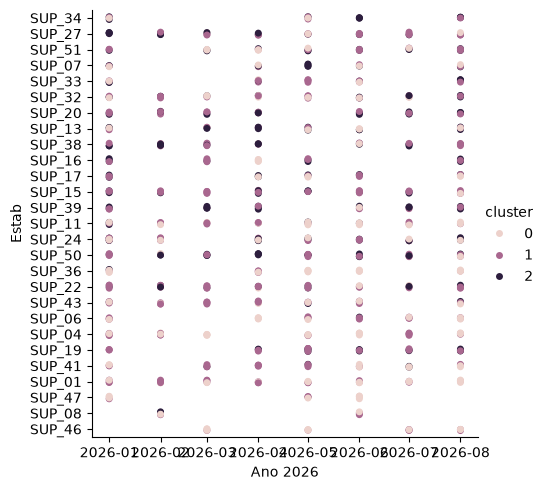

In [51]:
for y, df_ano in enumerate(dfs_ano):
    # sns.scatterplot(data = df_2[df_2["Mes_Ano_Data"].dt.year == y], x = "Mes_Ano_Data", y = "Preco", hue="")
    sns.catplot(data = df_ano, x = "Mes_Ano_Data", y = "Estab", hue="cluster")
    plt.xlabel(f"Ano {years[y]}")
    plt.show()

- Silhueta por grupo: usamos k = 3 para dividir os preços em barato, "normal" e caro. Para conferir se cada uma dessas faixas está bem definida, calculamos a silhueta média dos pontos de cada grupo, em cada produto e ano (vai de -1 a 1; quanto mais perto de 1, mais separado o grupo está dos outros).

In [52]:
nomes_grupos = {0: "Barato", 1: "Normal", 2: "Caro"}

silhuetas = []
for produto in df_2["Produto"].unique():
    for ano in years:
        dados_ano = df_2[(df_2["Produto"] == produto) & (df_2["Mes_Ano_Data"].dt.year == ano)]

        # a silhueta precisa de mais amostras do que grupos
        if dados_ano.shape[0] <= 3:
            continue

        scaler = StandardScaler()
        x_scaled = scaler.fit_transform(dados_ano[["PPK_Relativo"]])

        kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
        kmeans.fit(x_scaled)

        # se os preços forem quase todos iguais, o KMeans pode achar menos de 2 grupos
        if len(set(kmeans.labels_)) < 2:
            continue

        # mesma ordenação das funções de mercado: 0 = barato, 1 = normal, 2 = caro
        centros = kmeans.cluster_centers_.ravel()
        ordem = sorted(range(3), key=lambda c: centros[c])
        novo_rotulo = {antigo: novo for novo, antigo in enumerate(ordem)}
        rotulos = np.array([novo_rotulo[l] for l in kmeans.labels_])

        # silhueta de cada ponto, depois a média dentro de cada grupo
        silhueta_pontos = silhouette_samples(x_scaled, rotulos)
        for grupo in set(rotulos):
            silhuetas.append({
                "Produto": produto,
                "Ano": ano,
                "Grupo": nomes_grupos[grupo],
                "Silhueta": silhueta_pontos[rotulos == grupo].mean(),
            })

df_silhueta = pd.DataFrame(silhuetas)
print("Silhueta média por grupo:")
print(df_silhueta.groupby("Grupo")["Silhueta"].mean().reindex(["Barato", "Normal", "Caro"]).round(2))
df_silhueta.pivot_table(index=["Produto", "Ano"], columns="Grupo", values="Silhueta")[["Barato", "Normal", "Caro"]].round(2)

Silhueta média por grupo:
Grupo
Barato    0.57
Normal    0.56
Caro      0.51
Name: Silhueta, dtype: float64


Grupo         Barato  Normal  Caro
Produto Ano                       
Arroz   2022    0.55    0.58  0.51
        2023    0.59    0.52  0.57
        2024    0.61    0.52  0.55
        2025    0.58    0.55  0.50
        2026    0.65    0.57  0.55
...              ...     ...   ...
Óleo    2022    0.61    0.55  0.48
        2023    0.58    0.59  0.50
        2024    0.56    0.51  0.38
        2025    0.57    0.50  0.38
        2026    0.58    0.58  0.48

[84 rows x 3 columns]

In [53]:
# alguns estabelecimentos podem vender diferentes marcas
# levando em consideracao que +marcas e -preco = melhor mercado com ofertas
def melhor_mercado(dados: pd.DataFrame, grupo: int) -> list[str]:
    """
    Grupos: 
        0 - mais barato
        1 - preço médio
        2 - mais caros
    """
    estab_mais_aparecem: dict[str, int] = {}
    dados_filtrado = dados[dados["cluster"] == grupo]
    
    if dados_filtrado.empty:
        return []
        
    for estab in dados_filtrado["Estab"]:
        if estab not in estab_mais_aparecem:
            estab_mais_aparecem[estab] = 1
        else:
            estab_mais_aparecem[estab] += 1

    maior_qntd_ofertas = max(estab_mais_aparecem.values())
    melhores_estabs = [
        estab for estab, qntd in estab_mais_aparecem.items() if qntd == maior_qntd_ofertas
    ]
    
    return melhores_estabs


In [54]:
def melhor_mercado_pelo_produto(dados: pd.DataFrame, produto: str, ano: int, grupo: int, coluna:str = "Produto") -> tuple[list[str], str]:
    try:
        produto_escolhido = produto
        dados_produto = dados[dados[coluna] == produto_escolhido]
        dados_ano = dados_produto[dados_produto["Mes_Ano_Data"].dt.year == ano].copy()
        
        #proteção contra poucos dados para o número de clusters do K-Means
        total_amostras = dados_ano.shape[0]
        if total_amostras == 0:
            return (["nenhum"], produto)
            
        n_clusters = 3 if total_amostras >= 3 else total_amostras
        
        scaler = StandardScaler()
        x_scaled = scaler.fit_transform(dados_ano[["PPK_Relativo"]])

        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
        kmeans.fit(x_scaled)

        centros = kmeans.cluster_centers_.ravel()
        ordem = sorted(range(n_clusters), key=lambda c: centros[c])
        novo_rotulo = {antigo: novo for novo, antigo in enumerate(ordem)}
        dados_ano['cluster'] = [novo_rotulo[l] for l in kmeans.labels_]

        return (melhor_mercado(dados_ano, grupo), produto)
        
    except Exception as e:
        return (["nenhum"], produto)


In [55]:
def melhor_mercado_todos_produtos(dados:pd.DataFrame, ano:int, grupo:int, coluna:str = "Produto", mostrar_rank:bool = False)->dict[str,list[str]]|None:
    estab_mais_aparecem:dict[str,list[str]] = {}
    produtos:list[str] = list(dados[coluna].dropna().unique())
    produtos_do_ano:list[str] = list(dados[dados["Mes_Ano_Data"].dt.year == ano][coluna].dropna().unique())
    for p in produtos:
        if(p in produtos_do_ano):
            mercados, produto = melhor_mercado_pelo_produto(dados, p, ano, grupo, coluna)
            for m in mercados:
                if(m not in estab_mais_aparecem):
                    estab_mais_aparecem[m] = [produto]
                else:
                    estab_mais_aparecem[m].append(produto)
    estab_mais_aparecem = dict(
        sorted(estab_mais_aparecem.items(), key=lambda item: len(item[1]), reverse=True)
    )
    if(mostrar_rank):
        print(f"Melhores mercados de {ano}:")
        for i, e in enumerate(estab_mais_aparecem):
            print(f" {i+1}° - {e}:\n\tItens: {', '.join(estab_mais_aparecem[e])}")
    return estab_mais_aparecem

In [56]:
def melhor_mercado_todos_anos(dados: pd.DataFrame, grupo: int, coluna:str = "Produto",mostrar_rank: bool = False) -> dict[str, int]|None:
    """
    Mostra o mercado que mais vezes foi o 'melhor do ano' ao longo de todos os anos.
    """
    estab_mais_aparecem: dict[str, int] = {}
    anos_lista = sorted(dados["Mes_Ano_Data"].dt.year.unique())
    
    for ano in anos_lista:
        mercados_dict = melhor_mercado_todos_produtos(dados, ano, grupo, coluna)

        if not mercados_dict:
            continue
        
        primeiro_mercado = list(mercados_dict.keys())[0]
        if primeiro_mercado not in estab_mais_aparecem:
            estab_mais_aparecem[primeiro_mercado] = 1  # primeira vez que aparece na história dos anos
        else:
            estab_mais_aparecem[primeiro_mercado] += 1 # apareceu em mais um ano
    
    if(mostrar_rank):
        estab_mais_aparecem = dict(
            sorted(estab_mais_aparecem.items(), key=lambda item: item[1], reverse=True)
        )
        print("Mercados:")
        for mercado, vitorias in estab_mais_aparecem.items():
            if grupo == 2:
                print(f"- {mercado}: Foi caro em {vitorias} ano(s)")
            if grupo == 1:
                print(f"- {mercado}: Foi 'mediano' em {vitorias} ano(s)")
            if grupo == 0:
                print(f"- {mercado}: Foi barato em {vitorias} ano(s)")
        return None
    else:
        return estab_mais_aparecem


Se posto "melhor_mercado_todos_produtos(df_2, 2026, 0)", veremos que o Supermercado 04 e o Supermercado 01 empataram com 7 itens de baixo preço cada, mas em produtos diferentes: o Supermercado 04 se destaca em Arroz, Café, Pão, Farinha e Frango Sobrecoxa, e o Supermercado 01 em Feijão, Açúcar, Carne Bovina Acem, Ovo e Macarrão. Os dois têm Manteiga e Óleo baratos.

In [57]:
melhor_mercado_todos_produtos(df_2, 2026, 0, mostrar_rank = True)

Melhores mercados de 2026:
 1° - SUP_04:
	Itens: Manteiga, Arroz, Café, Pão, Farinha, Óleo, Frango Sobrecoxa
 2° - SUP_01:
	Itens: Manteiga, Feijão, Óleo, Açúcar, Carne Bovina Acem, Ovo, Macarrão
 3° - SUP_43:
	Itens: Tomate, Banana Nanica, Batata, Frango Sobrecoxa, Ovo
 4° - SUP_36:
	Itens: Arroz, Frango Peito, Pernil
 5° - SUP_11:
	Itens: Arroz, Banana Prata, Leite
 6° - SUP_24:
	Itens: Carne Bovina Coxão Mole, Frango Peito
 7° - SUP_41:
	Itens: Banana Nanica, Batata


{'SUP_04': ['Manteiga',
  'Arroz',
  'Café',
  'Pão',
  'Farinha',
  'Óleo',
  'Frango Sobrecoxa'],
 'SUP_01': ['Manteiga',
  'Feijão',
  'Óleo',
  'Açúcar',
  'Carne Bovina Acem',
  'Ovo',
  'Macarrão'],
 'SUP_43': ['Tomate', 'Banana Nanica', 'Batata', 'Frango Sobrecoxa', 'Ovo'],
 'SUP_36': ['Arroz', 'Frango Peito', 'Pernil'],
 'SUP_11': ['Arroz', 'Banana Prata', 'Leite'],
 'SUP_24': ['Carne Bovina Coxão Mole', 'Frango Peito'],
 'SUP_41': ['Banana Nanica', 'Batata']}

Uma conclusão sobre qual mercado é o melhor durante os anos pode se tornar imprecisa por depender da quantidade de amostras feitas pelos anos, se o mercado foi visitado no ano, ou se ele existiu desde 2022 (primeiro ano de coleta), o que pode tornar a resposta enviesada por ocorrência.

In [58]:
melhor_mercado_todos_anos(df_2, 2, mostrar_rank = True)

/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/sklearn/base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_33: Foi caro em 2 ano(s)
- SUP_32: Foi caro em 2 ano(s)
- SUP_16: Foi caro em 1 ano(s)


Existem alguns mercados que acabarão sendo os mais baratos por serem os únicos ou um dos poucos que vendem o produto.

In [59]:
melhor_mercado_todos_anos(df_2, 0, mostrar_rank = True)

/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/sklearn/base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_04: Foi barato em 2 ano(s)
- SUP_12: Foi barato em 1 ano(s)
- SUP_06: Foi barato em 1 ano(s)
- SUP_43: Foi barato em 1 ano(s)


- Implementando Filtro (Carne Bovina -> Carne, Frango Coxão -> Frango, Pão Francês -> Pão)

In [60]:
def adicionar_filtro(dados:pd.DataFrame)->pd.DataFrame:
    produtos_unitarios:list[str] = dados["Produto"].unique()
    lista_unitarios:list[str] = []
    for p in produtos_unitarios:
        if(search(r" ", p)):
            lista = p.split()[0]
            if(lista not in lista_unitarios):
                lista_unitarios.append(lista)
        else:
            if(p not in lista_unitarios):
                lista_unitarios.append(p)

    padrao_regex = "^(" + "|".join(lista_unitarios) + ")"
    dados["Produto_Filtro"] = dados["Produto"].str.extract(padrao_regex)
    dados.loc[dados["Produto"] == "Pernil", "Produto_Filtro"] = "Carne"
    return dados

df_2 = adicionar_filtro(df_2)

- Exibindo os melhores mercados com um filtro genérico, podemos ver que as classificações mudaram. Antes encontraríamos o Supermercado 33, junto ao 32, como os de preço alto durante 2 anos, mas quando pomos os nomes dos alimentos para algo genérico, vemos que nenhum nesta categoria foi o maior no ranking.

In [61]:
melhor_mercado_todos_anos(df_2, 2, "Produto", True)

/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/sklearn/base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_33: Foi caro em 2 ano(s)
- SUP_32: Foi caro em 2 ano(s)
- SUP_16: Foi caro em 1 ano(s)


In [62]:
# com filtro
# melhor_mercado_todos_produtos(df_2, 2022, 0, "Produto_Filtro")
melhor_mercado_todos_anos(df_2, 2, "Produto_Filtro", True)

Mercados:
- SUP_33: Foi caro em 1 ano(s)
- SUP_16: Foi caro em 1 ano(s)
- SUP_38: Foi caro em 1 ano(s)
- SUP_34: Foi caro em 1 ano(s)
- SUP_32: Foi caro em 1 ano(s)
